# 2 · Channel noise

*Roadmap:* [1 · Teleportation](01_teleportation.ipynb) → **2 · Channel noise** → [3 · Correction from counts](03_correction_from_counts.ipynb) → [4 · Automatic recalibration](04_automatic_recalibration.ipynb) → [5 · Incoherent noise and the ceiling](05_incoherent_noise_and_ceiling.ipynb) → [6 · Correlated noise](06_correlated_noise.ipynb) → [7 · Efficient learning and tracking](07_efficient_learning_and_tracking.ipynb) → [8 · Real hardware](08_real_hardware.ipynb) → [9 · Replication](09_replication.ipynb)

**Question.** A real link disturbs the channel qubits q2, q3 between the moment the Bell pairs are shared and
Alice's measurement. What does such noise do to Bob's state, and where in the protocol could it be undone?

**The noise.** Each channel qubit is turned by its own unknown rotation, as polarisation drift does in a fibre.
This is the coherent noise **N1** used throughout the study (and injected on the real device in notebook 8):

| channel qubit | rotation angle | rotation axis |
|---|---|---|
| q2 | 0.5 rad | (0.1, −0.5, −0.1), normalised |
| q3 | 1.3 rad | (−0.7, 1.0, 0.1), normalised |

Below, *strength s* multiplies both angles.

In [1]:
import sys
try:
    import telecorr
except ImportError:                       # running from a source checkout without installation
    sys.path.insert(0, "../src"); import telecorr

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize_scalar
from telecorr import protocol as P, channels as C
from telecorr.paulis import bloch
from telecorr.rotations import correction_rotations, u_matrix
from telecorr.states import MESSAGES, message_state, T_GATE, H
from telecorr.twirl import message_fidelity, f_avg_of
from telecorr.ceiling import ceiling
from telecorr.plotting import use_style, CONDITION, MESSAGE, INK_2
from telecorr.report import md_table, show
use_style()
MSG = {n: message_state(n) for n in MESSAGES}
U = C.coherent_unitaries()
legs_N1 = {2: [U[2]], 3: [U[3]]}

## The model: every branch is pure, the average is mixed

In each of Alice's 16 outcome branches Bob's qubits are still in a **pure** state, but each branch carries a
*different* error, the noise rotation conjugated by that branch's Pauli. Bob cannot tell the branches apart (Alice's
outcomes are uniform), so his state is the average. Averaging a channel over the four Paulis is a *Pauli twirl*
(Theorem T2.4): whatever acts on channel qubit q, Bob receives the Pauli channel whose Bloch shrink factors are the
diagonal of the channel's 3 × 3 transfer matrix T,

$$\lambda = \mathrm{diag}(T), \qquad p_I = \frac{1 + \operatorname{tr} T}{4}, \qquad
F_\text{avg} = \frac{4\, p_I^{(q2)} p_I^{(q3)} + 1}{5}.$$

So Bob is mixed although every branch is pure (Theorem T2.5). The table follows Bob's qubit q5 (which carries
message qubit q1 through q3) for the message `product_HT`:

In [2]:
r = P.teleport(MSG["product_HT"], legs=legs_N1)
a1 = bloch(np.outer(T_GATE @ H @ [1, 0], (T_GATE @ H @ [1, 0]).conj()))      # Alice's qubit q1
rows, avg = [], np.zeros(3)
for m1 in (0, 1):
    for m3 in (0, 1):
        idx = [m for m in range(16) if (m >> 1) & 1 == m1 and (m >> 3) & 1 == m3]
        pr = sum(r["p"][m] for m in idx)
        rho5 = sum(r["p"][m] * np.trace(r["branches"][m].reshape(2, 2, 2, 2), axis1=1, axis2=3) for m in idx) / pr
        v = bloch(rho5); avg += pr * v
        rows.append((f"m1 = {m1}, m3 = {m3}", pr, np.linalg.norm(v), 0.5 * (1 + v @ a1)))
rows.append(("average over the outcomes", 1.0, np.linalg.norm(avg), 0.5 * (1 + avg @ a1)))
show(md_table(rows, ["Alice's outcome on (q1, q3)", "probability", "|Bloch vector| of q5", "fidelity with Alice's q1"], 4))

| Alice's outcome on (q1, q3) | probability | |Bloch vector| of q5 | fidelity with Alice's q1 |
|---|---|---|---|
| m1 = 0, m3 = 0 | 0.2500 | 1.0000 | 0.9866 |
| m1 = 0, m3 = 1 | 0.2500 | 1.0000 | 0.6447 |
| m1 = 1, m3 = 0 | 0.2500 | 1.0000 | 0.9866 |
| m1 = 1, m3 = 1 | 0.2500 | 1.0000 | 0.6447 |
| average over the outcomes | 1.0000 | 0.6435 | 0.8157 |

## Result: the fidelity of the two messages

In [3]:
rows = []
for n in MESSAGES:
    rho = P.teleport(MSG[n], legs=legs_N1)["bob"]
    Tn = {q: C.T_matrix(legs_N1[q]) for q in (2, 3)}
    rows.append((n, P.fidelity(MSG[n], rho), P.purity(rho), message_fidelity(MSG[n], correction_rotations(None), Tn)))
show(md_table(rows, ["message", "F (exact simulation)", "purity of Bob's state", "F (twirl model)"], 6))

| message | F (exact simulation) | purity of Bob's state | F (twirl model) |
|---|---|---|---|
| product_HT | 0.789767 | 0.664620 | 0.789767 |
| bell_30_70 | 0.607412 | 0.458297 | 0.607412 |

The fidelity depends on the strength in a non-monotonic way: a rotation by 2π is no error at all, so the curve
turns (Proposition P2.7). The circles mark the exact minima on [0, 4].

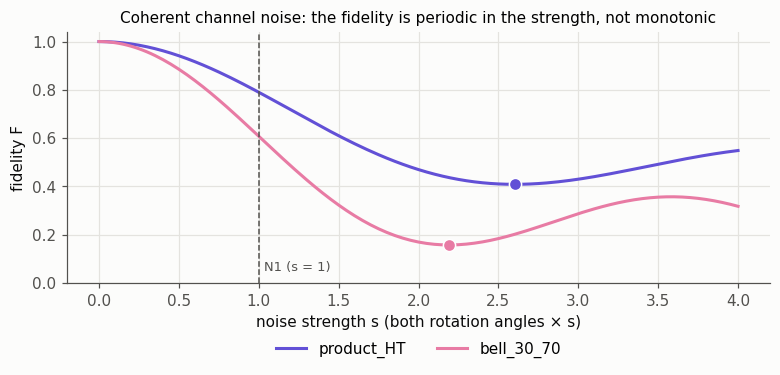

| message | strength at the minimum | minimum F |
|---|---|---|
| product_HT | 2.6011 | 0.4081 |
| bell_30_70 | 2.1911 | 0.1567 |

In [4]:
s = np.linspace(0, 4, 161)
F = {n: [] for n in MESSAGES}
T_of = lambda st: C.leg_T(strength=st)
for st in s:
    Tn = T_of(st)
    for n in MESSAGES:
        F[n].append(message_fidelity(MSG[n], correction_rotations(None), Tn))
fig, ax = plt.subplots(figsize=(7.2, 3.6))
mins = []
for n, col in MESSAGE.items():
    ax.plot(s, F[n], color=col, label=n)
    m = minimize_scalar(lambda st: message_fidelity(MSG[n], correction_rotations(None), T_of(st)), bounds=(1.5, 3.5), method="bounded",
                        options={"xatol": 1e-10})
    mins.append((n, m.x, m.fun)); ax.plot([m.x], [m.fun], "o", color=col, mec="white", ms=8)
ax.axvline(1.0, color=INK_2, lw=1, ls="--"); ax.text(1.03, 0.05, "N1 (s = 1)", color=INK_2, fontsize=8.5)
ax.set_xlabel("noise strength s (both rotation angles × s)"); ax.set_ylabel("fidelity F"); ax.set_ylim(0, 1.04)
ax.set_title("Coherent channel noise: the fidelity is periodic in the strength, not monotonic", fontsize=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2); plt.tight_layout(); plt.show()
show(md_table(mins, ["message", "strength at the minimum", "minimum F"], 4))

## Where can the noise be undone?

* **On Bob's side, after teleportation.** If Bob knew the message, the best unitary he could apply reaches the
  largest eigenvalue of his state (Proposition P2.13). For an *unknown* message no Bob-side operation improves the
  average fidelity at all (Theorem T2.14): the twirl has already spread the error over the branches.
* **On the channel qubits, before Alice's measurement.** There the error is still the same in every branch, so a
  fixed rotation that inverts it restores F = 1 for every message.

In [5]:
rng = np.random.default_rng(7)
base = P.average_fidelity(legs=legs_N1)
best_random_box = max(P.average_fidelity(legs=legs_N1, bob_box={4: u_matrix(*rng.uniform(-np.pi, np.pi, 3)), 5: u_matrix(*rng.uniform(-np.pi, np.pi, 3))})
                      for _ in range(40))
inv = {q: U[q].conj().T for q in (2, 3)}
rows = [("no correction", *[P.fidelity(MSG[n], P.teleport(MSG[n], legs=legs_N1)["bob"]) for n in MESSAGES], base),
        ("best Bob-side unitary, message known (λ_max)", *[np.linalg.eigvalsh(P.teleport(MSG[n], legs=legs_N1)["bob"])[-1] for n in MESSAGES], None),
        ("best of 40 random Bob-side boxes, message unknown", None, None, best_random_box),
        ("inverse rotation on the channel qubits", *[P.fidelity(MSG[n], P.teleport(MSG[n], legs=legs_N1, correction=inv)["bob"]) for n in MESSAGES],
         P.average_fidelity(legs=legs_N1, correction=inv))]
show(md_table(rows, ["correction", "F product_HT", "F bell_30_70", "Haar-average F"], 4))

| correction | F product_HT | F bell_30_70 | Haar-average F |
|---|---|---|---|
| no correction | 0.7898 | 0.6074 | 0.6760 |
| best Bob-side unitary, message known (λ_max) | 0.7963 | 0.6074 | - |
| best of 40 random Bob-side boxes, message unknown | - | - | 0.4177 |
| inverse rotation on the channel qubits | 1.0000 | 1.0000 | 1.0000 |

## Coherent versus incoherent noise

Coherent noise is special: it is a unitary error, so a unitary undoes it. Incoherent noise (depolarizing, amplitude
damping, dephasing) mixes the state, and no unitary correction can undo it. Below each incoherent channel acts on both
channel qubits with the strength p that causes the same damage as N1 (the same mean fidelity of the two messages).
The *ceiling* is the best Haar-average fidelity any unitary correction on the channel qubits can reach
(it is computed in closed form in notebook 5).

In [6]:
target = np.mean([P.fidelity(MSG[n], P.teleport(MSG[n], legs=legs_N1)["bob"]) for n in MESSAGES])
KIND = {"depolarizing": "depol", "amplitude damping": "amp", "dephasing": "phase"}
rows = [("coherent rotations N1", "-", target, f_avg_of(correction_rotations(None), C.leg_T()), ceiling(C.leg_T())[1])]
for kind, key in KIND.items():
    Tk = lambda p: {q: C.incoherent_T(**{key: p}) for q in (2, 3)}
    meanF = lambda p: np.mean([message_fidelity(MSG[n], correction_rotations(None), Tk(p)) for n in MESSAGES])
    p = brentq(lambda p: meanF(p) - target, 1e-9, 1.0)
    rows.append((kind, p, meanF(p), f_avg_of(correction_rotations(None), Tk(p)), ceiling(Tk(p))[1]))
show(md_table(rows, ["noise on q2 and q3", "strength p", "mean F of the two messages", "Haar-average F, no correction",
                     "ceiling: best unitary correction"], 4))

| noise on q2 and q3 | strength p | mean F of the two messages | Haar-average F, no correction | ceiling: best unitary correction |
|---|---|---|---|---|
| coherent rotations N1 | - | 0.6986 | 0.6760 | 1.0000 |
| depolarizing | 0.2786 | 0.6986 | 0.7006 | 0.7006 |
| amplitude damping | 0.4220 | 0.6986 | 0.6801 | 0.6801 |
| dephasing | 0.6159 | 0.6986 | 0.7247 | 0.7247 |

## What it means

* Noise on the channel qubits reaches Bob as a Pauli channel: each branch is pure, the average is mixed, and the
  fidelity follows from the diagonal of T alone (the twirl).
* Once teleportation is over the error cannot be removed for an unknown message. **The correction must act on the
  channel qubits, before Alice's measurement**, where a fixed inverse rotation restores F = 1 exactly.
* Only the coherent part of the noise can be undone. Incoherent noise of the same strength cannot be improved by
  any unitary.

**Next (notebook 3):** the inverse needs the noise, and the noise is unknown. Can the correction be learned from
measurement counts alone?